# 20nodes_EB_obsconf0_latconf0_Gaussian_Linear: benchmark



In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("benchmark")
from scipy.stats import spearmanr
from varsortability import calculate_varsortability
from condition_data import load_sample, sample_path


def sortability(frame, study):
    rows = []
    for family, seed in (
        frame[["dataset", "dataset_seed"]].drop_duplicates().itertuples(index=False, name=None)
    ):
        path = sample_path({"tuned": "evaluation"}.get(study, study), family)
        with load_sample(study, family, int(seed)) as data:
            raw = "X_raw" in data.files
            result = calculate_varsortability(data["X_raw"] if raw else data["X"], data["true_adj"])
            if not raw:
                for key in (
                    "varsortability",
                    "n_ordered_variance_paths",
                    "n_tied_variance_paths",
                ):
                    result[key] = np.nan
        rows.append(
            dict(
                dataset=family,
                dataset_seed=seed,
                study=study,
                raw_variance_available=raw,
                sample_path=str(path.relative_to(ROOT)),
                **result,
            )
        )
    return pd.DataFrame(rows)


In [2]:


output = ROOT / "results"
output.mkdir(parents=True, exist_ok=True)
sources = th.load_aligned_sources()
main = sources["benchmark_with_biological"]
complete = sources["complete"]
correlations = []
(output / "benchmark" / "by_family" / '20nodes_EB_obsconf0_latconf0_Gaussian_Linear').mkdir(parents=True, exist_ok=True)


## Metrics, seed stability and sortability


,model,mean,std,size
0,AVICI,0.446184,0.113053,15
1,DAGMA_Linear,0.189695,0.088932,15
2,DAGMA_Nonlinear,0.127557,0.061664,15
3,DAS,0.107358,0.056255,15
4,DirectLiNGAM,0.333148,0.089045,15
5,FCI,0.088630,0.063446,15
6,GES,0.393808,0.179204,15
7,GOLEM,0.125411,0.047655,15
8,GRaSP,0.794479,0.098063,15
9,GraNDAG,0.050703,0.033839,15


,model,mean,std,size
0,AVICI,56.400000,10.581655,15
1,DAGMA_Linear,60.266667,8.995766,15
2,DAGMA_Nonlinear,72.853333,10.923433,15
3,DAS,104.666667,12.821114,15
4,DirectLiNGAM,105.600000,17.356761,15
5,FCI,59.875556,9.870297,15
6,GES,89.400000,34.442084,15
7,GOLEM,85.533333,11.831355,15
8,GRaSP,23.168889,14.850383,15
9,GraNDAG,56.533333,6.390469,15


,model,mean,std,size
0,AVICI,0.476502,0.110435,15
1,DAGMA_Linear,0.245147,0.108341,15
2,DAGMA_Nonlinear,0.148249,0.077491,15
3,DAS,0.086002,0.045346,15
4,DirectLiNGAM,0.238864,0.068792,15
5,FCI,0.612374,0.262024,15
6,GES,0.315706,0.188638,15
7,GOLEM,0.117199,0.045179,15
8,GRaSP,0.790400,0.124021,15
9,GraNDAG,0.453333,0.309133,15


,model,mean,std,size
0,AVICI,0.432627,0.133500,15
1,DAGMA_Linear,0.156707,0.077951,15
2,DAGMA_Nonlinear,0.115402,0.054020,15
3,DAS,0.143574,0.075398,15
4,DirectLiNGAM,0.552912,0.126851,15
5,FCI,0.049363,0.038996,15
6,GES,0.550486,0.150187,15
7,GOLEM,0.136634,0.052642,15
8,GRaSP,0.806818,0.071486,15
9,GraNDAG,0.027249,0.018522,15


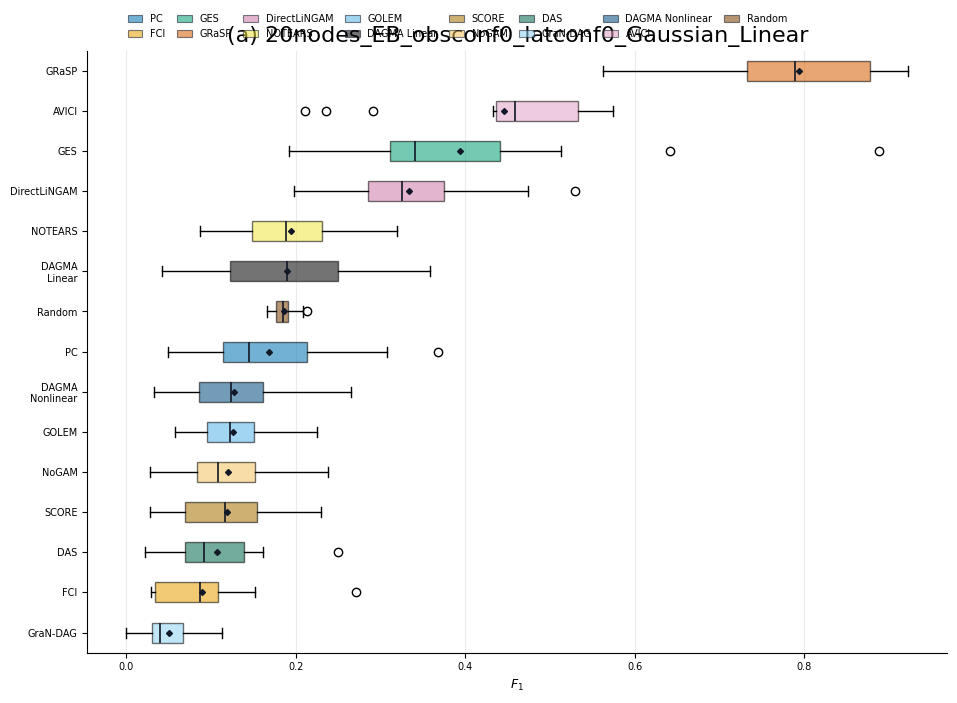

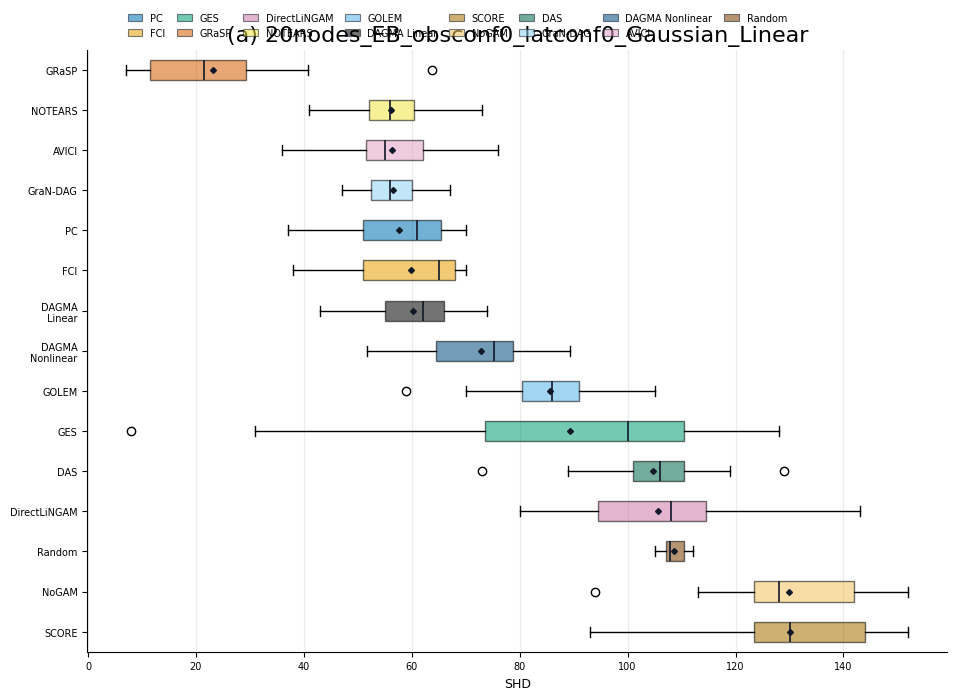

,dataset_seed,model,f1_range
0,13,AVICI,0.000000
1,13,DAGMA_Linear,0.000000
2,13,DAGMA_Nonlinear,0.141954
3,13,DAS,0.000000
4,13,DirectLiNGAM,0.000000
5,13,FCI,0.000000
6,13,GES,0.000000
7,13,GOLEM,0.000000
8,13,GRaSP,0.316327
9,13,GraNDAG,0.000000


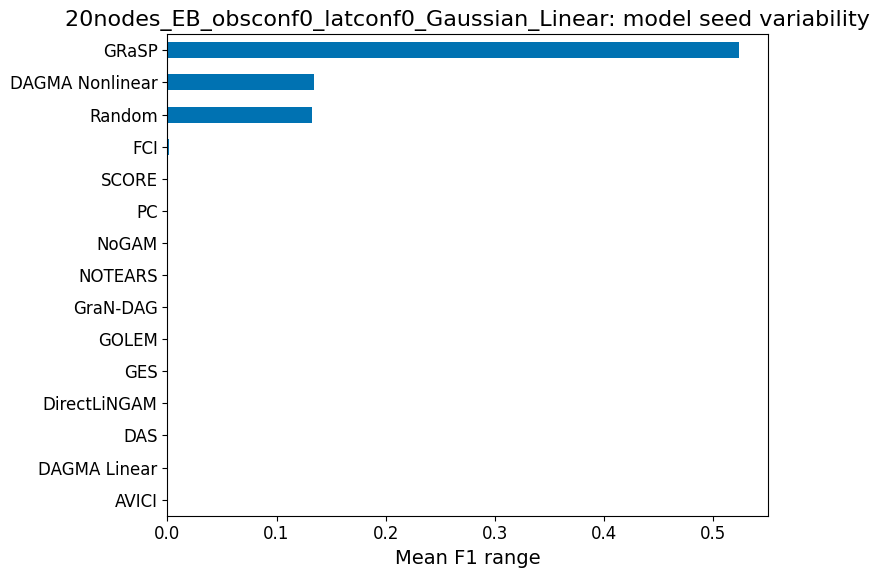

,model_seed,model,f1_range
0,0,AVICI,0.364186
1,0,DAGMA_Linear,0.316228
2,0,DAGMA_Nonlinear,0.295022
3,0,DAS,0.227654
4,0,DirectLiNGAM,0.331980
5,0,FCI,0.242615
6,0,GES,0.696970
7,0,GOLEM,0.168421
8,0,GRaSP,0.728261
9,0,GraNDAG,0.112676


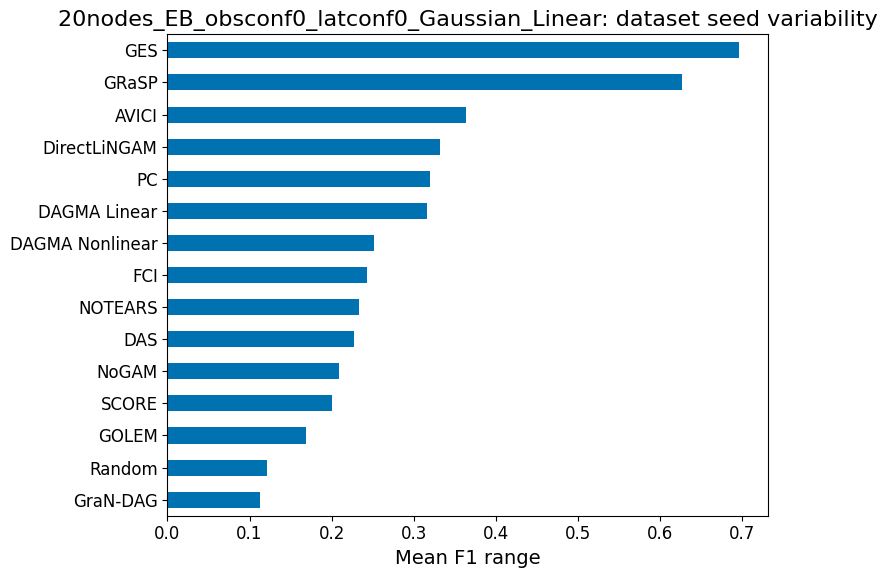

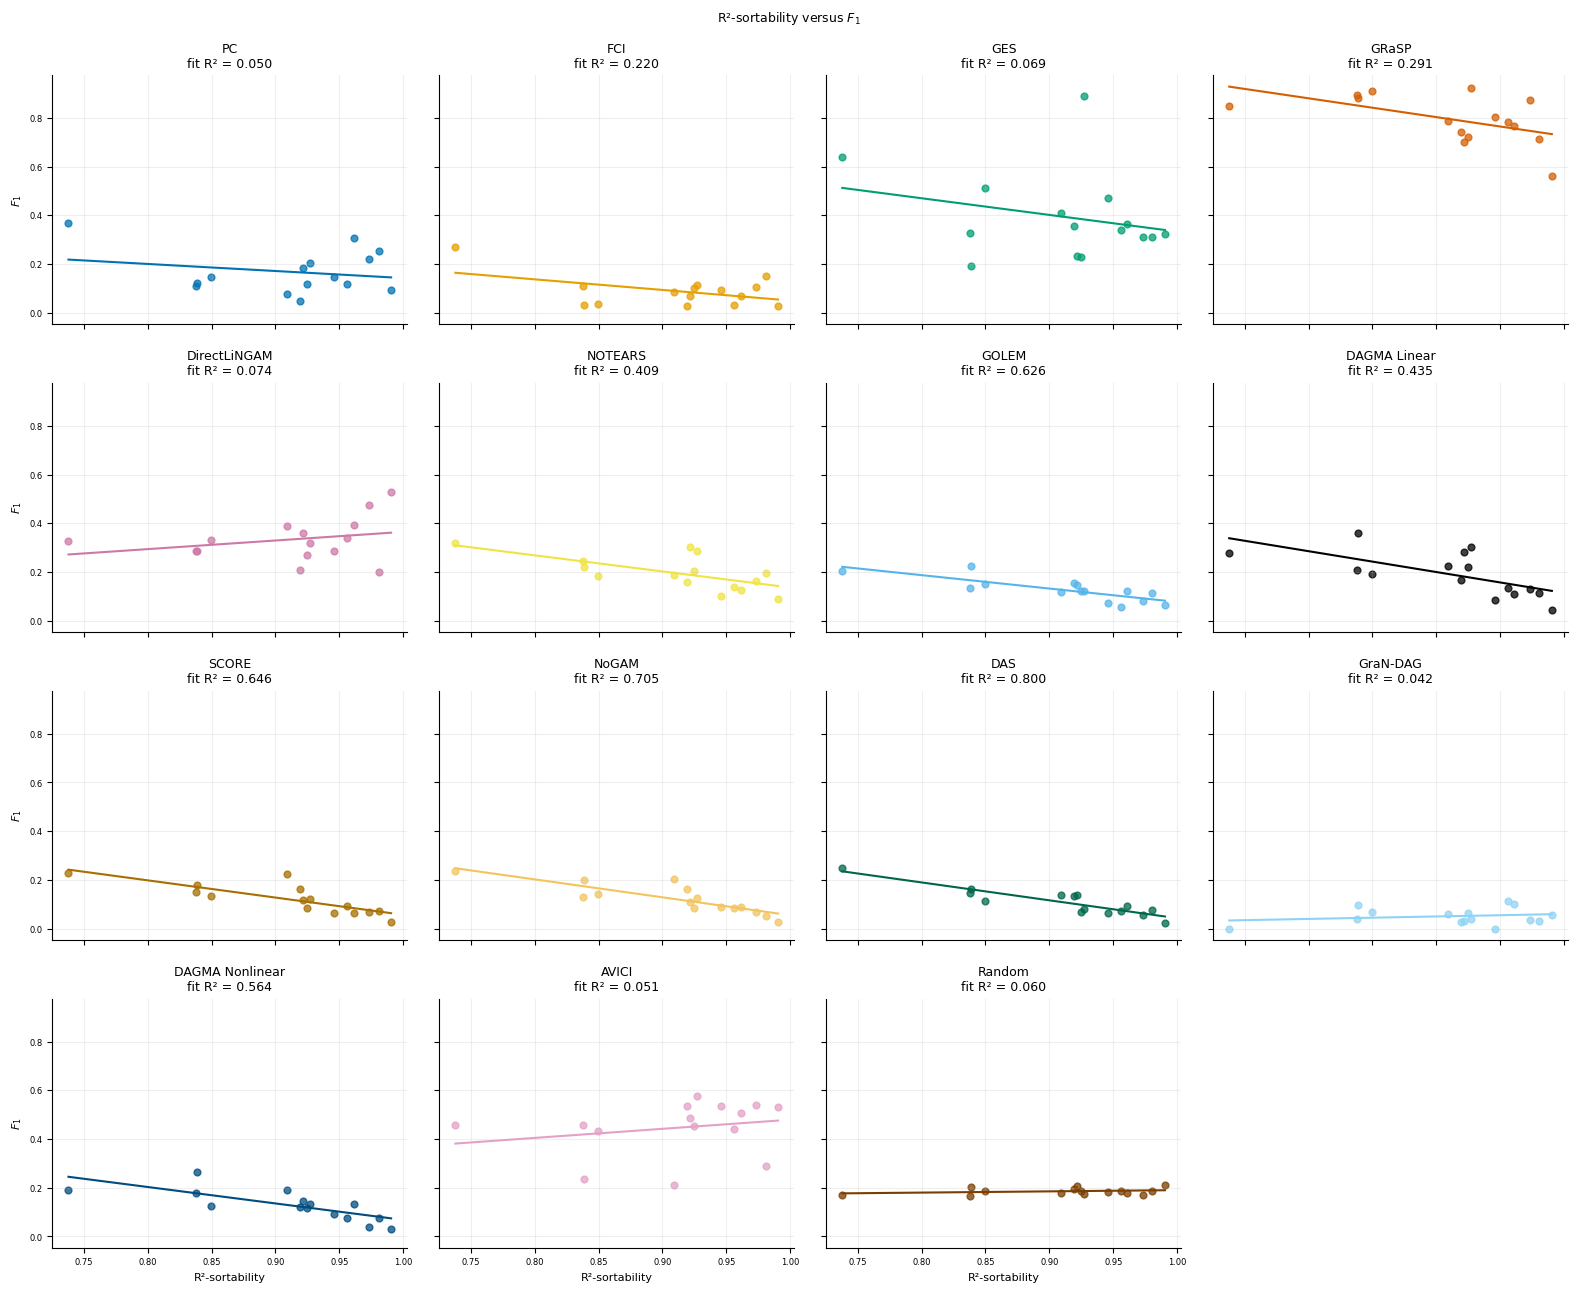

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,13,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,AVICI,0.458716,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963351,0.837696,191,184,0,160,0,20,2000
1,13,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Linear,0.209302,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963351,0.837696,191,184,0,160,0,20,2000
2,13,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Nonlinear,0.176467,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963351,0.837696,191,184,0,160,0,20,2000
3,13,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAS,0.145695,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963351,0.837696,191,184,0,160,0,20,2000
4,13,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DirectLiNGAM,0.287293,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963351,0.837696,191,184,0,160,0,20,2000
5,13,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,FCI,0.109091,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963351,0.837696,191,184,0,160,0,20,2000
6,13,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GES,0.325843,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963351,0.837696,191,184,0,160,0,20,2000
7,13,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GOLEM,0.132231,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963351,0.837696,191,184,0,160,0,20,2000
8,13,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GRaSP,0.894803,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963351,0.837696,191,184,0,160,0,20,2000
9,13,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GraNDAG,0.037736,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963351,0.837696,191,184,0,160,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,13,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963351,0.837696,191,184,0,160,0,20,2000
1,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,21,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958491,0.924528,265,254,0,245,0,20,2000
2,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,29,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.978125,0.956250,320,313,0,306,0,20,2000
3,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,32,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.991620,0.918994,358,355,0,329,0,20,2000
4,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,44,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.938416,0.838710,341,320,0,286,0,20,2000
5,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,47,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.996226,0.973585,265,264,0,258,0,20,2000
6,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,52,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.996094,0.921875,256,255,0,236,0,20,2000
7,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,71,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.983264,0.945607,239,235,0,226,0,20,2000
8,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,75,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.971671,0.909348,353,343,0,321,0,20,2000
9,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,102,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,1.000000,0.980695,259,259,0,254,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.226498,0.051301,0.373577,0.105645,0.416934,0.350000,0.200945
1,DAGMA_Linear,15,-0.659664,0.435157,-0.855890,0.969893,0.007458,-0.717857,0.002581
2,DAGMA_Nonlinear,15,-0.751070,0.564107,-0.675690,0.743492,0.001249,-0.839286,0.000091
3,DAS,15,-0.894538,0.800198,-0.734162,0.776593,0.000007,-0.860714,0.000038
4,DirectLiNGAM,15,0.272510,0.074262,0.354018,0.010438,0.325789,0.289286,0.295665
5,FCI,15,-0.469555,0.220482,-0.434638,0.484830,0.077406,-0.134048,0.633870
6,GES,15,-0.261736,0.068506,-0.684300,1.017590,0.346025,-0.203571,0.466795
7,GOLEM,15,-0.791195,0.625989,-0.550077,0.626841,0.000443,-0.810714,0.000246
8,GRaSP,15,-0.539432,0.290987,-0.771751,1.497979,0.037959,-0.507143,0.053664
9,GraNDAG,15,0.205338,0.042164,0.101373,-0.041705,0.462853,0.105451,0.708385


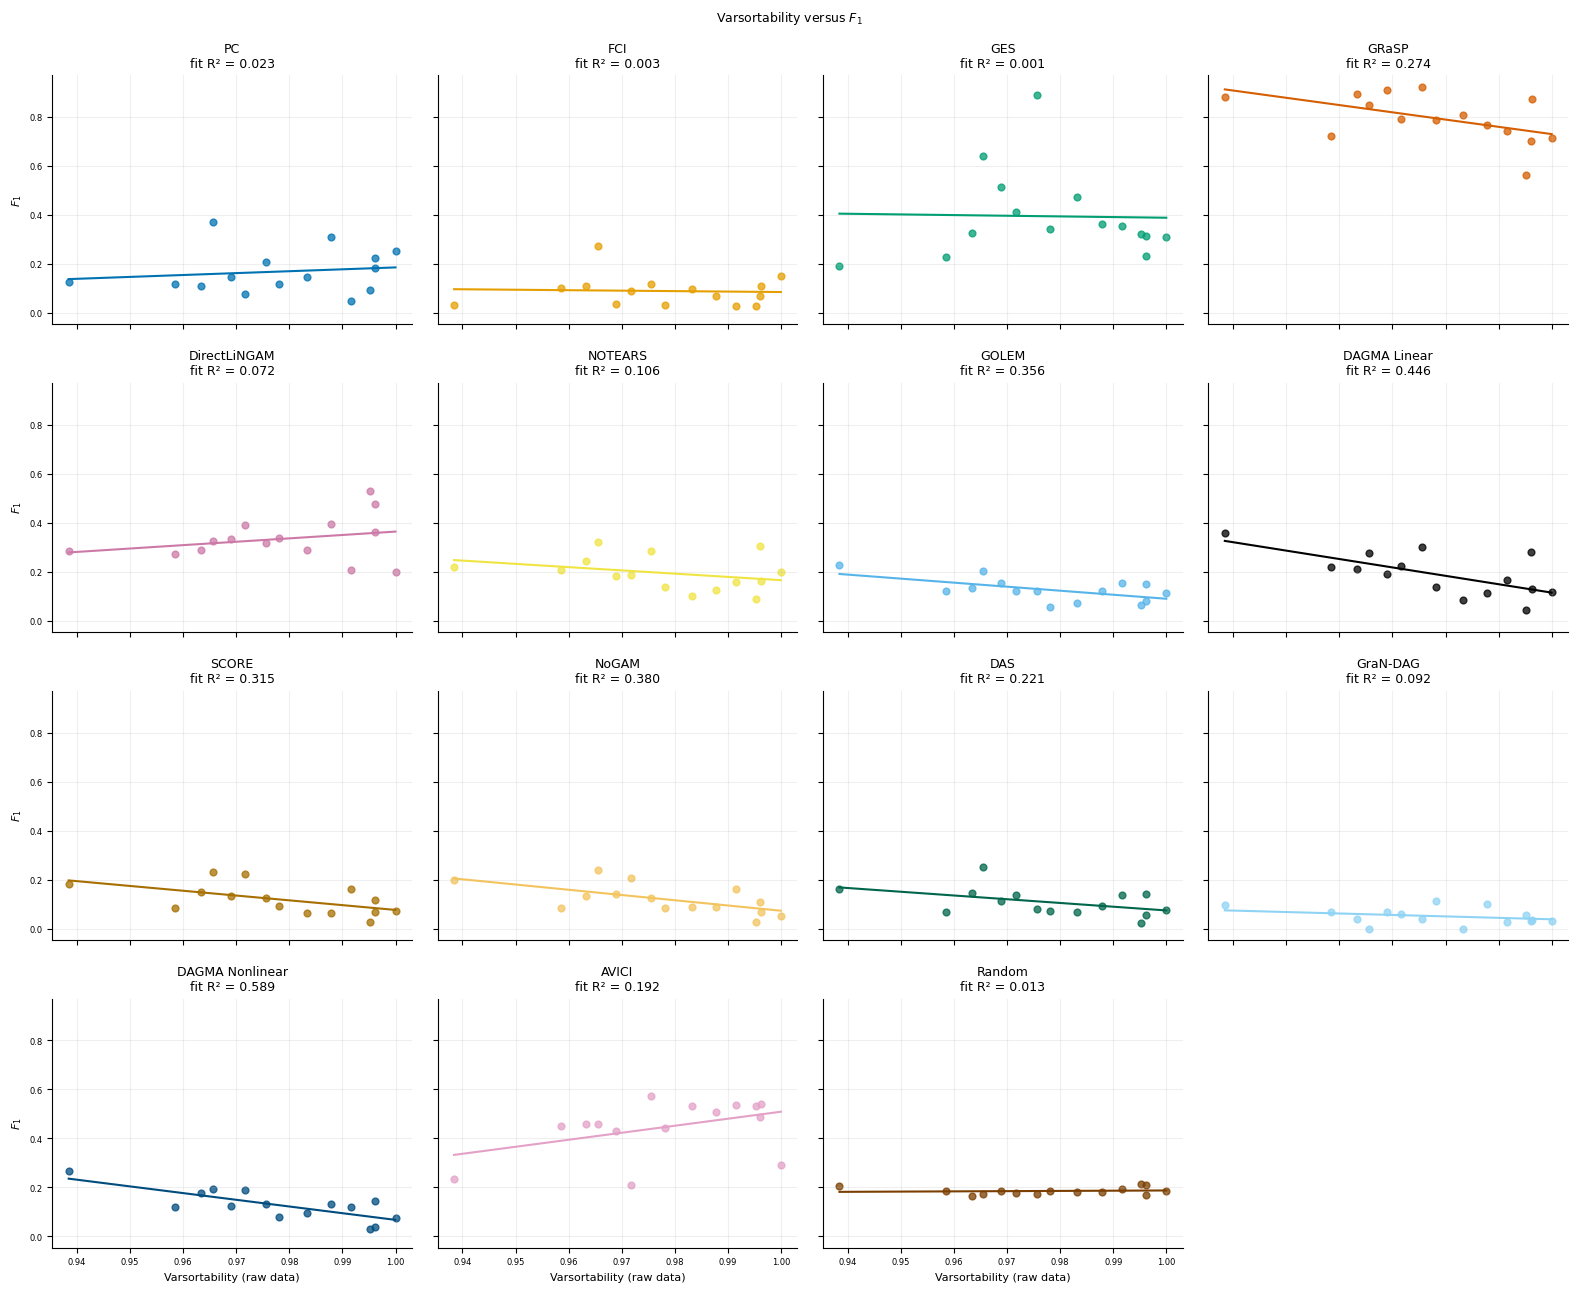

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,13,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,AVICI,0.458716,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963351,0.837696,191,184,0,160,0,20,2000
1,13,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Linear,0.209302,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963351,0.837696,191,184,0,160,0,20,2000
2,13,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Nonlinear,0.176467,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963351,0.837696,191,184,0,160,0,20,2000
3,13,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAS,0.145695,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963351,0.837696,191,184,0,160,0,20,2000
4,13,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DirectLiNGAM,0.287293,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963351,0.837696,191,184,0,160,0,20,2000
5,13,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,FCI,0.109091,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963351,0.837696,191,184,0,160,0,20,2000
6,13,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GES,0.325843,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963351,0.837696,191,184,0,160,0,20,2000
7,13,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GOLEM,0.132231,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963351,0.837696,191,184,0,160,0,20,2000
8,13,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GRaSP,0.894803,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963351,0.837696,191,184,0,160,0,20,2000
9,13,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GraNDAG,0.037736,15,20,EB,0,0,Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963351,0.837696,191,184,0,160,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,13,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.963351,0.837696,191,184,0,160,0,20,2000
1,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,21,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.958491,0.924528,265,254,0,245,0,20,2000
2,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,29,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.978125,0.956250,320,313,0,306,0,20,2000
3,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,32,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.991620,0.918994,358,355,0,329,0,20,2000
4,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,44,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.938416,0.838710,341,320,0,286,0,20,2000
5,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,47,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.996226,0.973585,265,264,0,258,0,20,2000
6,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,52,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.996094,0.921875,256,255,0,236,0,20,2000
7,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,71,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.983264,0.945607,239,235,0,226,0,20,2000
8,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,75,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.971671,0.909348,353,343,0,321,0,20,2000
9,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,102,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,1.000000,0.980695,259,259,0,254,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.438416,0.192209,2.862298,-2.353222,0.102117,0.421429,0.117699
1,DAGMA_Linear,15,-0.667674,0.445788,-3.429042,3.543392,0.006530,-0.578571,0.023847
2,DAGMA_Nonlinear,15,-0.767504,0.589063,-2.733134,2.800637,0.000837,-0.635714,0.010861
3,DAS,15,-0.469667,0.220587,-1.525795,1.599626,0.077326,-0.485714,0.066426
4,DirectLiNGAM,15,0.268782,0.072244,1.382151,-1.018634,0.332714,0.275000,0.321211
5,FCI,15,-0.051134,0.002615,-0.187355,0.271869,0.856385,-0.076854,0.785441
6,GES,15,-0.026069,0.000680,-0.269786,0.657666,0.926523,-0.107143,0.703901
7,GOLEM,15,-0.596722,0.356077,-1.642196,1.731524,0.018858,-0.510714,0.051725
8,GRaSP,15,-0.523169,0.273706,-2.962749,3.692129,0.045368,-0.532143,0.041159
9,GraNDAG,15,-0.303513,0.092120,-0.593119,0.630789,0.271452,-0.344951,0.207967


In [3]:
for study, frame in [("benchmark", main)]:
    frame = frame.loc[frame.dataset.eq('20nodes_EB_obsconf0_latconf0_Gaussian_Linear')].copy()
    values = sortability(frame, study)
    arms = (
        [("untuned", frame)]
        if study == "benchmark"
        else list(frame.groupby("arm", observed=True))
    )
    for arm, arm_frame in arms:
        for family, group in arm_frame.groupby("dataset", observed=True):
            family_output = output / study / "by_family" / family / arm
            family_output.mkdir(parents=True, exist_ok=True)
            data = th.visualization_data(group)
            # F1 and SHD, precision and recall retain dataset-level blocks.
            for metric in ("f1", "SHD", "precision", "recall"):
                blocks = (
                    group.loc[group.finished]
                    .groupby(["dataset_seed", "model"])[metric]
                    .mean()
                    .reset_index()
                )
                summary = (
                    blocks.groupby("model")[metric].agg(["mean", "std", "size"]).reset_index()
                )
                display(summary.head(20))
            for metric in ("f1", "SHD"):
                fig, _, _ = fv.plot_metric_boxplot_grid(
                    data,
                    [{"title": family, "datasets": family}],
                    metric=metric,
                    coverage_policy="all",
                    ncols=1,
                    figsize=(10, 7),
                    font_size=9,
                )
                fig.savefig(family_output / f"{metric}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
            # Stability only from recorded fits; invariant models remain zero.
            ok = group.loc[group.finished]
            model_range = (
                ok.groupby(["dataset_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            dataset_range = (
                ok.groupby(["model_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            for kind, table in [
                ("model_seed", model_range),
                ("dataset_seed", dataset_range),
            ]:
                display(table.head(20))
                summary = table.groupby("model").f1_range.mean().sort_values()
                fig, ax = plt.subplots(figsize=(8, 6))
                summary.rename(index=th.model_label).plot.barh(ax=ax)
                ax.set(
                    xlabel="Mean F1 range",
                    ylabel="",
                    title=f"{family}: {kind.replace('_', ' ')} variability",
                )
                fig.tight_layout()
                fig.savefig(family_output / f"{kind}_stability.pdf")
                display(fig)
                plt.close(fig)
            v = values.loc[values.dataset.eq(family)]
            for score in ("r2_sortability", "varsortability"):
                if v[score].notna().sum() < 3:
                    continue
                fig, _, details = fv.plot_varsortability_vs_f1(
                    data,
                    metric="f1",
                    datasets=family,
                    varsortability_values=v,
                    sortability=score,
                    coverage_policy="all",
                    columns=4,
                    include_r2_sort_regress=False,
                    obs_conf=None,
                    lat_conf=None,
                    font_size=8,
                    title_size=9,
                )
                fig.savefig(family_output / f"{score}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
                for key, table in details.items():
                    if isinstance(table, pd.DataFrame):
                        display(table.head(20))
                blocks = (
                    ok.groupby(["dataset_seed", "model"])
                    .f1.mean()
                    .reset_index()
                    .merge(v, on="dataset_seed")
                )
                for model, g in blocks.groupby("model"):
                    valid = g[["f1", score]].dropna()
                    constant = valid.nunique().min() < 2
                    r = (
                        None
                        if len(valid) < 3 or constant
                        else spearmanr(valid[score], valid.f1)
                    )
                    correlations.append(
                        dict(
                            study=study,
                            arm=arm,
                            dataset=family,
                            model=model,
                            sortability=score,
                            n_pairs=len(valid),
                            rho=np.nan if r is None else r.statistic,
                            pvalue=np.nan if r is None else r.pvalue,
                            status="constant_or_insufficient" if r is None else "estimated",
                        )
                    )


In [4]:
corr = pd.DataFrame(correlations)
if len(corr):
    from statistical_methods import holm

    corr["pvalue_holm"] = np.nan
    valid = corr.pvalue.notna()
    corr.loc[valid, "pvalue_holm"] = (
        corr.loc[valid]
        .groupby(["study", "arm", "sortability"])
        .pvalue.transform(lambda p: holm(p))
    )
display(corr.head(20))


,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
0,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,AVICI,r2_sortability,15,0.350000,0.200945,estimated,1.000000
1,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Linear,r2_sortability,15,-0.717857,0.002581,estimated,0.025812
2,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAGMA_Nonlinear,r2_sortability,15,-0.839286,0.000091,estimated,0.001096
3,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DAS,r2_sortability,15,-0.860714,0.000038,estimated,0.000495
4,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,DirectLiNGAM,r2_sortability,15,0.289286,0.295665,estimated,1.000000
5,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,FCI,r2_sortability,15,-0.134048,0.633870,estimated,1.000000
6,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GES,r2_sortability,15,-0.203571,0.466795,estimated,1.000000
7,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GOLEM,r2_sortability,15,-0.810714,0.000246,estimated,0.002706
8,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GRaSP,r2_sortability,15,-0.507143,0.053664,estimated,0.429309
9,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,GraNDAG,r2_sortability,15,0.105451,0.708385,estimated,1.000000
